Universidad Torcuato Di Tella

*Licenciatura en Tecnología Digital*

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**
# **Trabajo Práctico — Ejercicio N°5: Mediciones con ruido y mínimos cuadrados**

Antes de comenzar a resolver, importamos los módulos que utilizaremos en el desarrollo.

In [1]:
# Importamos los módulos
import numpy as np
import matplotlib.pyplot as plt

# Pandas es para armar la tabla
import pandas as pd

Además, corremos los bloques necesarios de ejercicios anteriores para poder realizar este ejercicio:

In [2]:
# Ejercicio 3

# Definimos `X_fantoma`
X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Aplanamos la matriz `X_fantoma` para dar lugar a `x_fantoma`
x_fantoma = X_fantoma.reshape(-1)

In [3]:
# Ejercicio 3
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

In [4]:
# Ejercicio 3
def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

In [5]:
# Ejercicio 4

# Para definir dimensiones de la matriz (nxn)
n = 8

D2 = [(1,0),(0,1)]
D4 = [(1,0),(0,1),(1,1),(1,-1)]
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]

# Construímos A2, A4, A7
A2 = matriz_proyeccion(n, D2)[0]
A4 = matriz_proyeccion(n, D4)[0]
A7 = matriz_proyeccion(n, D7)[0]

In [6]:
# Generemos las mediciones
b2 = A2 @ x_fantoma
b4 = A4 @ x_fantoma
b7 = A7 @ x_fantoma

Continuaremos utilizando el vector $x_\text{fantoma}$ del Ejercicio 1 y la matriz $A_7$. Las mediciones ideales son $b_7 = A_7 x_\text{fantoma}$. Para simular una adquisición real, agregaremos ruido y obtendremos mediciones perturbadas $b_\sigma = b_7 + \eta\sigma$. Debido al ruido, en general no existirá una imagen que reproduzca exactamente todas las mediciones. Utilizaremos mínimos cuadrados para encontrar la imagen cuyas mediciones simuladas sean lo más cercanas posible a $b_\sigma$.

1. Fijar una semilla aleatoria y generar un único vector $z$, del mismo tamaño que $b_7$, con componentes gaussianas estándar. Calcular `escala = np.sqrt(np.mean(b7**2))`; este valor representa el tamaño típico de las mediciones. Para cada $\sigma \in \{0, 0.01, 0.03, 0.06, 0.10\}$, definir $\eta_\sigma = \sigma \textbf{escala} z$ y construir $b_\sigma$. De este modo, $\sigma = 0,03$ representa un ruido cuya desviación estándar es aproximadamente el $3\%$ del tamaño típico de las mediciones.

Primero nos encargamos de generar los $\eta_\sigma$.

In [7]:
# Determinamos una semilla aleatoria para garantizar reproducibilidad
SEED = 73
np.random.seed(SEED)

# Creamos el vector z del mismo tamaño que b7, es decir, 119
z = np.random.normal(loc=0.0, scale=1.0, size=119)

# Creamos la lista de desvios (sigma's)
desvios = [0, 0.01, 0.03, 0.06, 0.1]

# Calculamos escala
escala = np.sqrt(np.mean(b7**2))

# Creamos la lista de ruidos (eta's) donde habrá una por cada desvio
ruidos = list()

for ds in desvios:
    ruido = ds * escala * z
    ruidos.append(ruido)

for i in range(len(ruidos)):
    print(ruidos[i])

[ 0.  0.  0.  0. -0. -0.  0. -0. -0.  0.  0. -0.  0. -0.  0. -0.  0. -0.
  0. -0. -0. -0. -0. -0.  0.  0.  0. -0.  0.  0. -0. -0. -0.  0. -0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0.  0. -0.  0.  0.  0.  0. -0.  0.
  0. -0.  0.  0.  0. -0.  0. -0. -0.  0. -0.  0.  0.  0. -0.  0.  0. -0.
 -0. -0. -0.  0.  0.  0. -0. -0.  0. -0.  0. -0.  0.  0. -0.  0. -0. -0.
 -0. -0. -0.  0. -0. -0. -0. -0. -0.  0. -0.  0. -0. -0. -0.  0. -0. -0.
  0. -0. -0. -0. -0. -0.  0.  0.  0.  0. -0.]
[ 6.32375691e-03  2.33639200e-02  2.67527858e-02  2.88692346e-03
 -1.64023738e-02 -4.02739078e-04  4.72183396e-03 -1.67680392e-02
 -8.00603360e-03  1.15258522e-02  1.77582235e-02 -1.75961941e-02
  3.62894669e-03 -2.31272753e-03  3.26899152e-03 -1.25647128e-02
  6.30784890e-03 -3.98960650e-03  3.99054175e-04 -5.70708324e-03
 -1.72828631e-04 -5.02571572e-04 -6.77980850e-03 -8.98808417e-03
  5.58916874e-03  1.15180779e-02  1.59002386e-03 -3.73689687e-03
  1.36396788e-02  1.81531824e-02 -2.99293796e-03 -3.94596597e

Luego, nos encargamos de generar los $b_\sigma$.

In [8]:
# Creamos la lista de mediciones con ruido (b_\sigma)
mediciones_ruidosas = list()

for i in range(len(ruidos)):
    med_ruido = b7 + ruidos[i]
    mediciones_ruidosas.append(med_ruido)

2. Para cada nivel de ruido, utilizar `np.linalg.lstsq` para obtener la reconstrucción $\hat{x}_\sigma$ que minimiza $||A_7x −b_\sigma||^2$. Registrar en una tabla la norma del ruido, la norma del residuo, el error relativo respecto de $x_\text{fantoma}$ y los valores mínimo y máximo de la reconstrucción. Visualizar las imágenes reconstruidas utilizando una misma escala de color.

In [9]:
# Creamos una lista con las reconstrucciones por mínimos cuadrados
reconstrucciones = list()

# Creamos una lista con los residuos cuadrados producto de las reconstrucciones
residuos_cuadrados = list()

for med_ruidosa in mediciones_ruidosas:
    # Resolvemos por mínimos cuadrados
    # Obtenemos el \hat{x}_\sigma
    x_ruidoso = np.linalg.lstsq(A7, med_ruidosa)[0]

    # Actualizamos la lista de reconstrucciones
    reconstrucciones.append(x_ruidoso)

    # Calculamos el residuo cuadrado correspondiente
    res_cuad = np.linalg.norm(A7 @ x_ruidoso - med_ruido)**2

    # Actualizamos la list ade residuos cuadrados
    residuos_cuadrados.append(res_cuad)

for rec in reconstrucciones:
    print(rec)

[ 1.63680891e-16 -1.44328993e-15  0.00000000e+00  1.66533454e-15
  6.10622664e-16  1.66533454e-16  1.24900090e-15  2.77555756e-16
  8.88178420e-16  6.24500451e-16  8.00000000e-01  3.00000000e-01
  3.00000000e-01  3.00000000e-01 -6.66133815e-16 -1.02695630e-15
 -1.40165657e-15  8.00000000e-01  8.00000000e-01  8.00000000e-01
  3.00000000e-01  3.00000000e-01  3.00000000e-01  4.37150316e-16
  1.94289029e-16  3.00000000e-01  8.00000000e-01  3.00000000e-01
  3.00000000e-01  3.00000000e-01  3.00000000e-01 -3.33066907e-16
 -1.62370117e-15  3.00000000e-01  3.00000000e-01  3.00000000e-01
  3.00000000e-01  5.00000000e-01  3.00000000e-01 -6.93889390e-16
  7.35522754e-16  3.00000000e-01  3.00000000e-01  3.00000000e-01
  5.00000000e-01  5.00000000e-01  5.00000000e-01 -2.08166817e-16
 -2.77555756e-16 -5.82867088e-16  3.00000000e-01  3.00000000e-01
  3.00000000e-01  5.00000000e-01 -4.44089210e-16 -3.88578059e-16
 -9.85322934e-16 -3.46944695e-16  5.55111512e-17  5.55111512e-17
 -1.52655666e-16  6.66133

Ahora seguimos con el cálculo de los errores relativos respecto a $x_\text{fantoma}$.

In [10]:
errores_relativos_ruidos = list()
for i in range(len(reconstrucciones)):
    errores_relativos_ruidos.append(np.linalg.norm(reconstrucciones[i] - x_fantoma)/np.linalg.norm(x_fantoma))

Luego, creamos y mostramos la tabla solicitada con los datos.

In [11]:
tabla_sigma = pd.DataFrame({
    'residuo_cuadrado': [residuos_cuadrados[0], residuos_cuadrados[1], residuos_cuadrados[2], residuos_cuadrados[3], residuos_cuadrados[4]],
    'norma_ruido': [np.linalg.norm(ruidos[0]), np.linalg.norm(ruidos[1]), np.linalg.norm(ruidos[2]), np.linalg.norm(ruidos[3]), np.linalg.norm(ruidos[4])],
    'norma_residuo':  [np.sqrt(residuos_cuadrados[0]), np.sqrt(residuos_cuadrados[1]), np.sqrt(residuos_cuadrados[2]), np.sqrt(residuos_cuadrados[3]), np.sqrt(residuos_cuadrados[4])],
    'error_relativo': [errores_relativos_ruidos[0], errores_relativos_ruidos[1], errores_relativos_ruidos[2], errores_relativos_ruidos[3], errores_relativos_ruidos[4]],
    'max_aten': [np.max(reconstrucciones[0]), np.max(reconstrucciones[1]), np.max(reconstrucciones[2]), np.max(reconstrucciones[3]), np.max(reconstrucciones[4])],
    'min_aten': [np.min(reconstrucciones[0]), np.min(reconstrucciones[1]), np.min(reconstrucciones[2]), np.min(reconstrucciones[3]), np.min(reconstrucciones[4])]
})

tabla_sigma

,residuo_cuadrado,norma_ruido,norma_residuo,error_relativo,max_aten,min_aten
0,1.492241,0.000000,1.221573,2.137106e-15,0.800000,-1.623701e-15
1,1.341758,0.122157,1.158343,2.031603e-02,0.809410,-1.661350e-02
2,1.088313,0.366472,1.043223,6.094810e-02,0.828231,-4.984051e-02
3,0.826948,0.732944,0.909367,1.218962e-01,0.856462,-9.968101e-02
4,0.700226,1.221573,0.836795,2.031603e-01,0.894103,-1.661350e-01


Finalmente, visualizamos todas las imágenes reconstruidas utilizando la escala gris de colores.

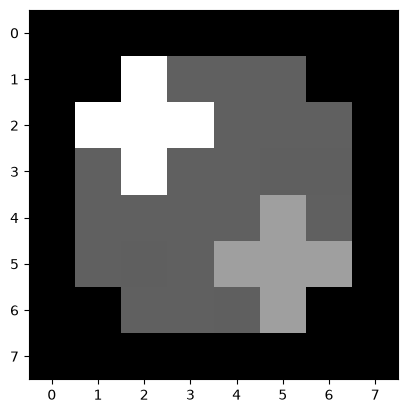

In [12]:
X_ruidoso_0 = reconstrucciones[0].reshape(8,8)

plt.imshow(X_ruidoso_0, cmap="gray")

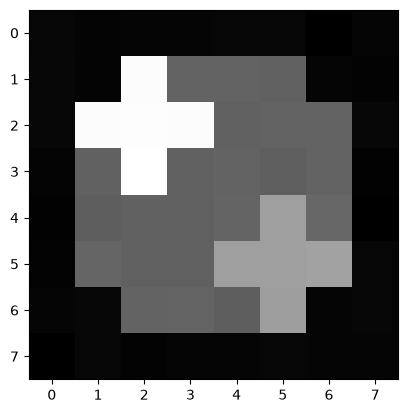

In [13]:
X_ruidoso_1 = reconstrucciones[1].reshape(8,8)

plt.imshow(X_ruidoso_1, cmap="gray")

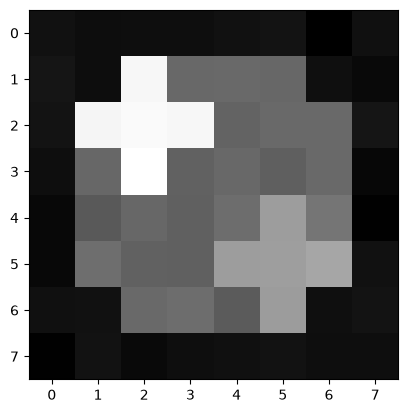

In [14]:
X_ruidoso_2 = reconstrucciones[2].reshape(8,8)

plt.imshow(X_ruidoso_2, cmap="gray")

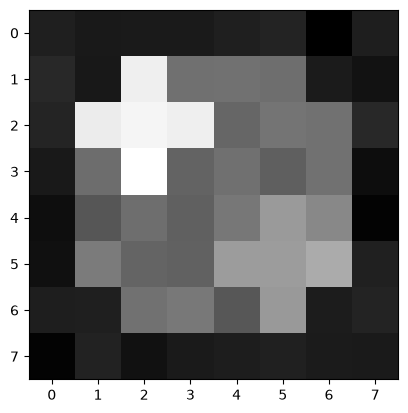

In [15]:
X_ruidoso_3 = reconstrucciones[3].reshape(8,8)

plt.imshow(X_ruidoso_3, cmap="gray")

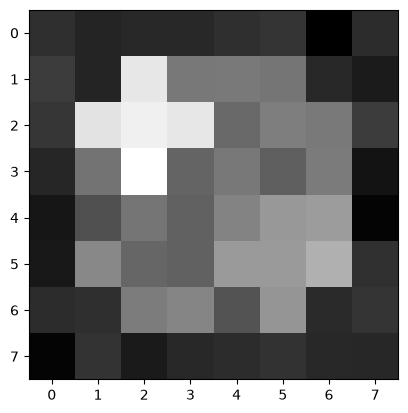

In [16]:
X_ruidoso_4 = reconstrucciones[4].reshape(8,8)

plt.imshow(X_ruidoso_4, cmap="gray")

3. Analizar los resultados: ¿cómo cambia el error de reconstrucción al aumentar \sigma? ¿Por qué el residuo deja de ser nulo cuando se agrega ruido? ¿Por qué pueden aparecer valores negativos, aunque los coeficientes de atenuación del fantoma sean no negativos?

Al aumentar $\sigma$, es decir, el ruido; el error de construcción $||x_{fantoma}\hat{x}_k||$ aumenta proporcionalmente.

La fórmula del residuo se puede reducir a la siguiente expresión:

$$r_{\sigma}=A_7(x_{fantoma}-\hat{x_\sigma})+\eta_\sigma$$

De esta manera, se puede observar que el residuo final no sólo es afectado por el error de reconstrucción, sino que también se ve directamente influido por el vector de ruidos. Así, la magnitud de los residuos es proporcional al nivel de ruido percibido.

Asimismo, la introducción de ruido en el problema puede ocasionar que algunas entradas de $b_\sigma$ sean negativas. En particular:

$$b_{\sigma,i} < 0 \iff b_{7,i} + \eta_{\sigma,i} < 0 \iff b_{7,i} < - \eta_{\sigma,i}$$

Si bien es improbable, esto podría llegar a ocurrir para alguna entrada. En consecuencia, para que $A_7\hat{x_\sigma} = b_\sigma$, la reconstrucción podría llegar a "exigir" que algún coeficiente de $\hat{x_\sigma}$ sea menor a cero para cumplir con el sistema.